<a href="https://colab.research.google.com/github/rlstjscks/2026-LA/blob/main/ex02_transform_tiefighter2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 라이브러리 선언

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

INF = 1000  # 그림판 크기
LEN = 100   # 처음 사각형의 크기


### 1. 2차원 변환 구현
* translate / rotate / scale / shear_x / shear_y
* reflect_x / reflect_y / reflect_origin / reflect_yx

모든 변환은 동차좌표 → 3×3 행렬 곱(`np.dot`) → 2차원 좌표 순서로 처리

In [2]:
# ───────────────────────── 1. 2차원 변환 함수 ─────────────────────────
# 모든 변환: 동차좌표계(3x1)로 바꾸고 -> 3x3 행렬과 곱하고 -> 2차원으로 되돌림
def _apply(m, p):
  hp = np.array([p[0], p[1], 1.0])   # 1. 동차좌표계로 변환
  q = np.dot(m, hp)                  # 2. 행렬과 벡터의 곱 (3,3) x (3,1)
  return np.array([q[0], q[1]])      # 3. 2차원 좌표계로 변환


def translate(p, dx, dy):            # 이동
  m = np.array([[1.0, 0.0, dx],
                [0.0, 1.0, dy],
                [0.0, 0.0, 1.0]])
  return _apply(m, p)


def rotate(p, theta):                # 회전 (원점 기준, 반시계, 단위: rad)
  c, s = np.cos(theta), np.sin(theta)
  m = np.array([[c, -s, 0.0],
                [s,  c, 0.0],
                [0.0, 0.0, 1.0]])
  return _apply(m, p)


def scale(p, sx, sy):                # 크기
  m = np.array([[sx, 0.0, 0.0],
                [0.0, sy, 0.0],
                [0.0, 0.0, 1.0]])
  return _apply(m, p)


def shear_x(p, sx):                  # 기울기(x축 방향): x' = x + sx*y
  m = np.array([[1.0, sx, 0.0],
                [0.0, 1.0, 0.0],
                [0.0, 0.0, 1.0]])
  return _apply(m, p)


def shear_y(p, sy):                  # 기울기(y축 방향): y' = y + sy*x
  m = np.array([[1.0, 0.0, 0.0],
                [sy, 1.0, 0.0],
                [0.0, 0.0, 1.0]])
  return _apply(m, p)


def reflect_x(p):                    # 반전(x축 대칭): (x, y) -> (x, -y)
  m = np.array([[1.0, 0.0, 0.0],
                [0.0, -1.0, 0.0],
                [0.0, 0.0, 1.0]])
  return _apply(m, p)


def reflect_y(p):                    # 반전(y축 대칭): (x, y) -> (-x, y)
  m = np.array([[-1.0, 0.0, 0.0],
                [0.0, 1.0, 0.0],
                [0.0, 0.0, 1.0]])
  return _apply(m, p)


def reflect_origin(p):               # 반전(원점 대칭): (x, y) -> (-x, -y)
  m = np.array([[-1.0, 0.0, 0.0],
                [0.0, -1.0, 0.0],
                [0.0, 0.0, 1.0]])
  return _apply(m, p)


def reflect_yx(p):                   # 반전(y=x 대칭): (x, y) -> (y, x)
  m = np.array([[0.0, 1.0, 0.0],
                [1.0, 0.0, 0.0],
                [0.0, 0.0, 1.0]])
  return _apply(m, p)


### 축 그리기 및 사각형 그리기

In [3]:
# ───────────────────────── 2. 그리기 기본 함수 ─────────────────────────
def draw_axis(ax):
  ax.axhline(0, color='black', alpha=0.3)  # x-axis line
  ax.axvline(0, color='black', alpha=0.3)  # y-axis line
  ax.set_xlim(-INF, INF)
  ax.set_ylim(-INF, INF)
  ax.set_aspect('equal')  # 정사각형 모양으로 backboard 그리기


def draw_rectangle(ax, p1, p2, p3, p4, color='#1f77b4', tf=None, zorder=1):
  pts = [p1, p2, p3, p4]
  if tf is not None:                       # 물체 전체에 적용할 추가 변환(선택)
    pts = [tf(p) for p in pts]
  ax.add_patch(Polygon(pts, color=color, zorder=zorder))


### 2. 파트 그리기
* draw_cockpit / draw_left_arm / draw_left_wing / draw_right_arm / draw_right_wing / draw_notch
* 오른쪽 파트는 왼쪽 파트를 `reflect_y`로 반전해서 생성

In [4]:
# ───────────────────────── 3. 파트 그리기 ─────────────────────────
def draw_cockpit(ax, p1, p2, p3, p4, color='#1f77b4', tf=None):  # 중앙 조종석
  pts = []
  for p in (p1, p2, p3, p4):
    q = translate(p, -LEN/2, -LEN/2)   # 1. 사각형 중심을 원점으로
    q = scale(q, 5, 5)                 # 2. 5배 확대 (한 변 500)
    q = rotate(q, np.pi/4)             # 3. 45도 회전 -> 마름모
    pts.append(q)
  draw_rectangle(ax, *pts, color=color, tf=tf)


def _make_part(p1, p2, p3, p4, width, h_a, h_b, cx):
  """정사각형(p1~p4)을 x방향 너비 width, 왼쪽 변 높이 h_a, 오른쪽 변 높이 h_b인
  사다리꼴로 만든 뒤 중심 x좌표를 cx로 옮긴다. (왼쪽 변: p1,p4 / 오른쪽 변: p2,p3)"""
  pts = []
  for p, h in ((p1, h_a), (p2, h_b), (p3, h_b), (p4, h_a)):
    q = translate(p, -LEN/2, -LEN/2)           # 1. 원점으로 이동
    q = scale(q, width/LEN, h/LEN)             # 2. 변마다 높이를 다르게 크기 변환
    q = translate(q, cx, 0)                    # 3. 제자리로 이동
    pts.append(q)
  return pts


def draw_left_arm(ax, p1, p2, p3, p4, color='#1f77b4', tf=None):   # 왼쪽 날개축
  # x: -750 ~ -250, 높이: 바깥 90 -> 안쪽 220
  pts = _make_part(p1, p2, p3, p4, width=500, h_a=90, h_b=220, cx=-500)
  draw_rectangle(ax, *pts, color=color, tf=tf)


def draw_left_wing(ax, p1, p2, p3, p4, color='#1f77b4', tf=None):  # 왼쪽 날개
  # x: -850 ~ -750, 높이: 바깥 1200 -> 안쪽 800
  pts = _make_part(p1, p2, p3, p4, width=100, h_a=1200, h_b=800, cx=-800)
  draw_rectangle(ax, *pts, color=color, tf=tf)


def draw_right_arm(ax, p1, p2, p3, p4, color='#1f77b4', tf=None):  # 오른쪽 날개축
  # 왼쪽 날개축을 y축 반전(reflect_y)해서 만든다
  pts = [reflect_y(q) for q in _make_part(p1, p2, p3, p4, 500, 90, 220, -500)]
  draw_rectangle(ax, *pts, color=color, tf=tf)


def draw_right_wing(ax, p1, p2, p3, p4, color='#1f77b4', tf=None): # 오른쪽 날개
  pts = [reflect_y(q) for q in _make_part(p1, p2, p3, p4, 100, 1200, 800, -800)]
  draw_rectangle(ax, *pts, color=color, tf=tf)


def draw_notch(ax, tf=None):  # 미적 요소: 날개축 위의 흰색 화살촉 홈
  base = [np.array([0.0, 0.0]),       # 끝점
          np.array([140.0, 20.0]),
          np.array([110.0, 0.0]),     # 안쪽으로 파인 점
          np.array([140.0, -20.0])]
  # 오른쪽: y축 반전 후 x=480으로 이동 -> 끝점 (480,0), 밑변 x=340
  right = [translate(reflect_y(p), 480, 0) for p in base]
  # 왼쪽: 오른쪽을 y축 반전
  left = [reflect_y(q) for q in right]
  for pts in (right, left):
    if tf is not None:
      pts = [tf(q) for q in pts]
    ax.add_patch(Polygon(pts, color='white', zorder=1.5))


### 3. TIE Fighter 그리기 (draw_object)

In [5]:
def draw_object(ax, tf=None, colors=None):
  p1 = np.array([0, 0])
  p2 = np.array([LEN, 0])
  p3 = np.array([LEN, LEN])
  p4 = np.array([0, LEN])
  c = colors or {}
  main_c = '#1f77b4'

  draw_left_wing(ax, p1, p2, p3, p4, c.get('wing', main_c), tf)
  draw_right_wing(ax, p1, p2, p3, p4, c.get('wing', main_c), tf)
  draw_left_arm(ax, p1, p2, p3, p4, c.get('arm', main_c), tf)
  draw_right_arm(ax, p1, p2, p3, p4, c.get('arm', main_c), tf)
  draw_cockpit(ax, p1, p2, p3, p4, c.get('cockpit', main_c), tf)
  draw_notch(ax, tf)


### 4. main

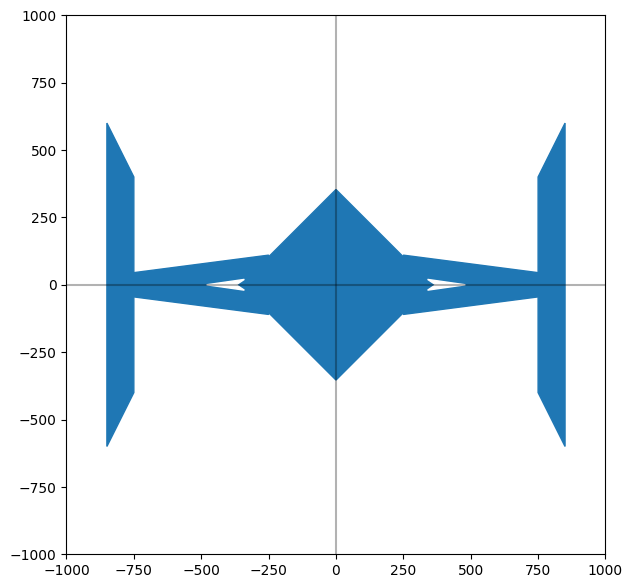

In [6]:
def main():
  fig, ax = plt.subplots(figsize=(7, 7))   # 그림판 선언 및 크기 설정
  draw_axis(ax)                            # 축 그리기
  draw_object(ax)                          # 물체 그리기
  plt.show()

main()


### 챌린지 (미적 요소 + 다른 객체)

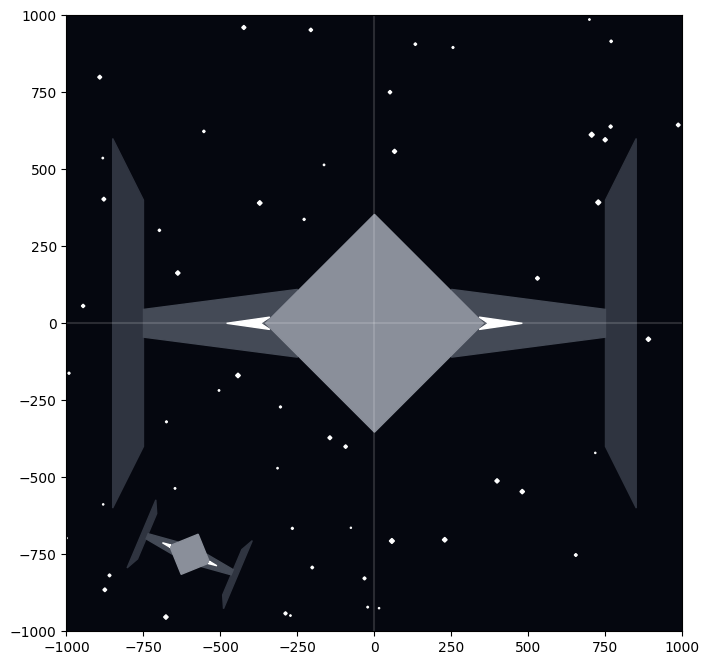

In [7]:
# ── 챌린지: 미적 요소 + 타이파이터 외 다른 객체 ──
# draw_object()에 tf(전체 변환 함수)를 넘기면 같은 물체를 이동/회전/크기 변환해서 여러 개 그릴 수 있다.
import random

def draw_stars(ax, n=60, seed=7):
  # 배경 별: 정사각형을 크기 변환 + 회전 + 이동해서 만든 작은 마름모
  rnd = random.Random(seed)
  p1, p2 = np.array([0, 0]), np.array([LEN, 0])
  p3, p4 = np.array([LEN, LEN]), np.array([0, LEN])
  for _ in range(n):
    s = rnd.uniform(0.03, 0.12)
    dx, dy = rnd.uniform(-INF, INF), rnd.uniform(-INF, INF)
    pts = []
    for p in (p1, p2, p3, p4):
      q = translate(p, -LEN/2, -LEN/2)
      q = scale(q, s, s)
      q = rotate(q, np.pi/4)
      q = translate(q, dx, dy)
      pts.append(q)
    draw_rectangle(ax, *pts, color='white', zorder=0.5)

fig, ax = plt.subplots(figsize=(8, 8))
ax.set_facecolor('#05070f')
draw_axis(ax)
for ln in ax.lines: ln.set_color('white'); ln.set_alpha(0.15)
draw_stars(ax)

colors = {'cockpit': '#8a8f9a', 'arm': '#444a56', 'wing': '#2f3440'}
# 큰 기체: 원본 / 작은 기체 1대: 크기 + 회전 + 이동 변환을 합성
draw_object(ax, colors=colors)
for (s, th, dx, dy) in [(0.2, -0.4, -600, -750)]:
  tf = lambda p, s=s, th=th, dx=dx, dy=dy: translate(rotate(scale(p, s, s), th), dx, dy)
  draw_object(ax, tf=tf, colors=colors)
plt.show()


### 챌린지 (my_utils.py 분리)
`my_utils.py`에 변환 함수, draw 함수, main을 모아 두었고 아래처럼 호출한다.

In [8]:
import my_utils
my_utils.main()


ModuleNotFoundError: No module named 'my_utils'